In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("customers.csv")

In [4]:
df.head()

,CustomerID,Age,Annual Income,Spending Score
0,C0001,23,87726,92
1,C0002,26,18860,28
2,C0003,41,61435,100
3,C0004,38,111119,74
4,C0005,33,121280,81


In [5]:
features = ["Age", "Annual Income", "Spending Score"]

In [6]:
X = df[features].dropna()

In [7]:
X.head()

,Age,Annual Income,Spending Score
0,23,87726,92
1,26,18860,28
2,41,61435,100
3,38,111119,74
4,33,121280,81


In [8]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
X_scaled

array([[-1.07317116,  0.35173686,  1.34489473],
       [-0.81712587, -1.51561367, -0.9570218 ],
       [ 0.46310058, -0.36116229,  1.6326343 ],
       ...,
       [ 0.71914587,  0.94112395,  0.26587136],
       [ 0.29240372,  0.78184627, -1.10089158],
       [ 1.23123645,  1.60394038, -0.41751011]], shape=(500, 3))

In [14]:
from scipy.cluster.hierarchy import (linkage, dendrogram)

In [16]:
Z = linkage(
    X_scaled,
    method= "ward",
    metric = "euclidean"
)

Text(0, 0.5, 'Ward Linkage Distance')

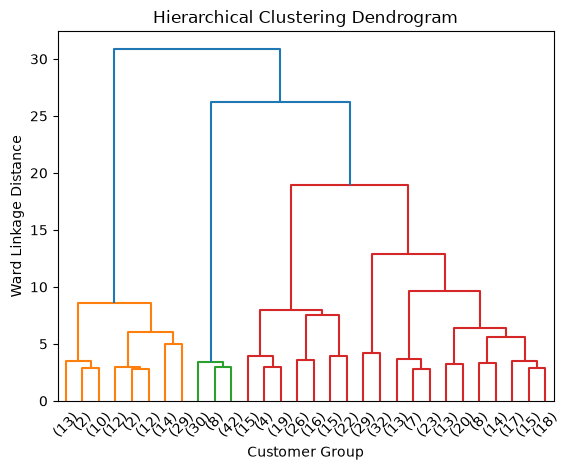

In [ ]:
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers Group")
plt.ylabel("Ward Linkage Distance")

In [21]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [22]:
optimal_k = 4

model = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage = 'ward'
)

label = model.fit_predict(X_scaled)


In [23]:
label

array([0, 2, 3, 3, 3, 0, 1, 3, 3, 3, 0, 0, 1, 3, 0, 2, 0, 0, 0, 0, 0, 3,
       0, 2, 1, 3, 1, 3, 0, 2, 3, 3, 0, 0, 0, 0, 0, 0, 0, 3, 1, 3, 3, 1,
       0, 3, 0, 1, 0, 1, 0, 1, 2, 3, 1, 0, 2, 0, 3, 3, 3, 3, 3, 0, 0, 1,
       3, 3, 0, 0, 3, 0, 3, 0, 0, 0, 0, 0, 0, 2, 3, 0, 3, 3, 0, 3, 0, 0,
       1, 0, 1, 3, 1, 2, 1, 0, 0, 0, 2, 2, 3, 1, 1, 3, 0, 3, 1, 1, 1, 3,
       3, 1, 3, 2, 1, 2, 1, 1, 2, 0, 3, 1, 0, 0, 2, 1, 1, 3, 0, 0, 2, 0,
       0, 0, 1, 2, 2, 0, 3, 0, 3, 2, 1, 0, 3, 0, 3, 1, 0, 2, 0, 0, 2, 2,
       0, 3, 0, 3, 0, 3, 1, 0, 1, 3, 0, 1, 2, 0, 3, 1, 0, 0, 3, 0, 0, 3,
       0, 0, 1, 2, 0, 2, 3, 0, 3, 3, 0, 1, 0, 0, 0, 3, 0, 0, 1, 0, 1, 2,
       3, 0, 0, 2, 0, 2, 3, 0, 3, 3, 2, 0, 0, 0, 2, 0, 2, 0, 0, 1, 3, 3,
       1, 3, 0, 0, 2, 1, 1, 3, 2, 0, 2, 3, 0, 3, 0, 2, 3, 1, 2, 1, 0, 2,
       1, 3, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 3, 0, 1, 1, 2, 0, 1, 2, 0, 0,
       0, 1, 0, 3, 2, 3, 2, 0, 0, 0, 2, 0, 2, 0, 0, 0, 3, 0, 2, 3, 3, 1,
       1, 3, 2, 0, 1, 0, 1, 0, 2, 1, 1, 1, 0, 0, 3,

In [24]:
#attach the cluster label

df_clustered = df.loc[X.index].copy()
df_clustered["Cluster"] = label

In [25]:
df_clustered

,CustomerID,Age,Annual Income,Spending Score,Cluster
0,C0001,23,87726,92,0
1,C0002,26,18860,28,2
2,C0003,41,61435,100,3
3,C0004,38,111119,74,3
4,C0005,33,121280,81,3
...,...,...,...,...,...
495,C0496,39,46183,74,0
496,C0497,19,21473,29,2
497,C0498,44,109462,62,3
498,C0499,39,103588,24,1


In [26]:
silhouette_score(X_scaled,label)

0.31416238586611056

In [27]:
df_clustered.groupby('Cluster')[features].mean()

,Age,Annual Income,Spending Score
Cluster,,,
0,30.306220,57582.014354,66.765550
1,50.457447,118964.212766,25.872340
2,24.662500,27926.125000,21.375000
3,40.487179,101929.769231,78.700855


Text(0, 0.5, 'Spending Score')

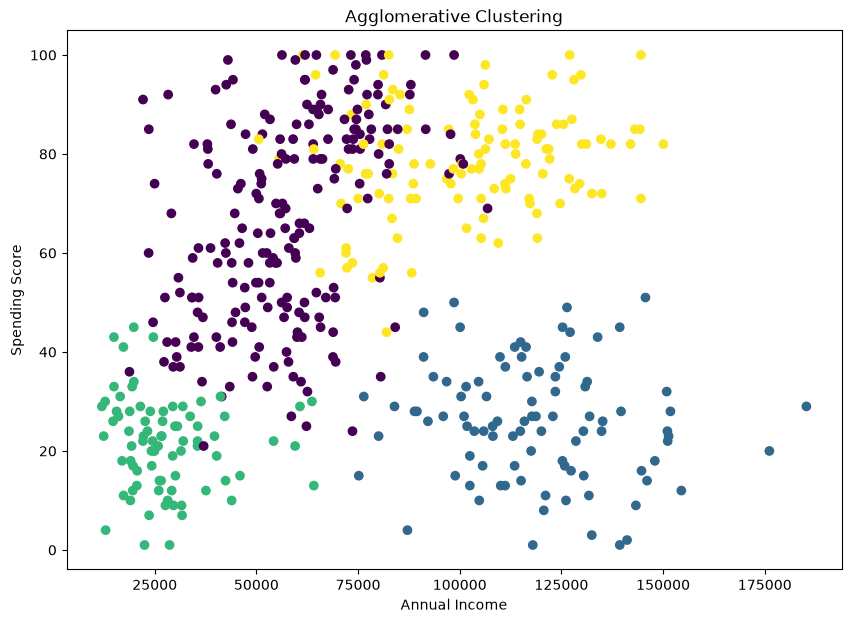

In [29]:
plt.figure(figsize=(10,7))

plt.scatter(
    df_clustered["Annual Income"],
    df_clustered["Spending Score"],
    c=label,
)

plt.title("Agglomerative Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")